# Лабораторна робота №5: Мультимодальні моделі для генерації описів зображень (Image Captioning)
## Частина 1: Аудит вхідних зображень, архітектура LLaVA та ініціалізація моделі

**Дисципліна:** Нейромережеві технології і системи  
**Тема:** Мультимодальні архітектури та генерація описів зображень  
**Варіант:** №2 — Генерація описів для кількох зображень з дослідженням впливу формулювання промпту, `temperature` та `max_new_tokens`  
**Студент:** Max  
**Університет:** Національний університет «Львівська політехніка»  

---

### Мета першого етапу:
1. Провести всебічний технічний та візуальний аудит набору із 4 різнопланових вхідних цифрових зображень (природа/пейзаж, міська сцена, інтер'єр/архітектура, інженерна лабораторія).
2. Дослідити архітектуру мультимодальної родини LLaVA (Large Language and Vision Assistant), зокрема структуру з'єднання зорового енкодера SigLIP та мовної моделі Qwen2 через мультимодальний проектор.
3. Перевірити апаратне середовище (CUDA, пам'ять відеокарти NVIDIA GeForce RTX 3050 Laptop GPU 4 ГБ VRAM) та завантажити модель `llava-hf/llava-interleave-qwen-0.5b-hf` у форматі FP16.
4. Здійснити базовий smoke-test генерації опису для підтвердження працездатності мультимодального конвеєра.

## 1. Діагностика середовища та динамічна роздільна здатність шляхів

Забезпечимо строгу CWD-незалежність виконання блокнота: базовий каталог визначається відносно файлової структури репозиторію незалежно від того, де саме запущено Jupyter-сервер.

In [1]:
import sys
import warnings
import platform
from pathlib import Path
from PIL import Image
import torch
import transformers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="IProgress not found.*")

def resolve_lab_dir() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / 'inputs' / '01_coastal_lighthouse.png').exists() and candidate.name == 'lab5_multimodal_captioning':
            return candidate
        if (candidate / 'lab5_multimodal_captioning' / 'inputs' / '01_coastal_lighthouse.png').exists():
            return candidate / 'lab5_multimodal_captioning'
    return cwd

def format_rel(p: Path, base: Path) -> str:
    try:
        rel = p.resolve().relative_to(base.resolve().parent)
        return rel.as_posix()
    except ValueError:
        return p.name

LAB_DIR = resolve_lab_dir()
INPUTS_DIR = (LAB_DIR / "inputs").resolve()
OUTPUTS_DIR = (LAB_DIR / "outputs").resolve()

print(f"Робочий каталог ЛР5: {format_rel(LAB_DIR, LAB_DIR)}")
print(f"Каталог зображень:   {format_rel(INPUTS_DIR, LAB_DIR)}")
print(f"Python версія:       {platform.python_version()}")
print(f"PyTorch версія:      {torch.__version__}")
print(f"Transformers версія: {transformers.__version__}")
print(f"CUDA доступність:    {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU пристрій:        {torch.cuda.get_device_name(0)}")
    print(f"Загальна VRAM:       {torch.cuda.get_device_properties(0).total_memory / (1024**2):.1f} MiB")

Робочий каталог ЛР5: lab5_multimodal_captioning
Каталог зображень:   lab5_multimodal_captioning/inputs
Python версія:       3.13.5
PyTorch версія:      2.14.1+cu130
Transformers версія: 5.17.0


CUDA доступність:    True
GPU пристрій:        NVIDIA GeForce RTX 3050 Laptop GPU
Загальна VRAM:       4095.5 MiB


## 2. Аудит та візуалізація 4 вхідних зображень

Відповідно до вимог Варіанта №2 підготовлено 4 візуально різнорідні зображення:
- `01_coastal_lighthouse.png` — природний прибережний пейзаж, маяк на скелі, хвилі, вечірнє освітлення.
- `02_cafe_bicycle.png` — європейська міська вулиця, велосипед біля столика кав'ярні, бруківка.
- `03_library_interior.png` — архітектурний інтер'єр бібліотеки, масивні дерев'яні полиці, книги, навчальна атмосфера.
- `04_modern_robotics_lab.png` — науково-дослідна лабораторія, роботизований маніпулятор, осцилограф, плата з мікрочипом.

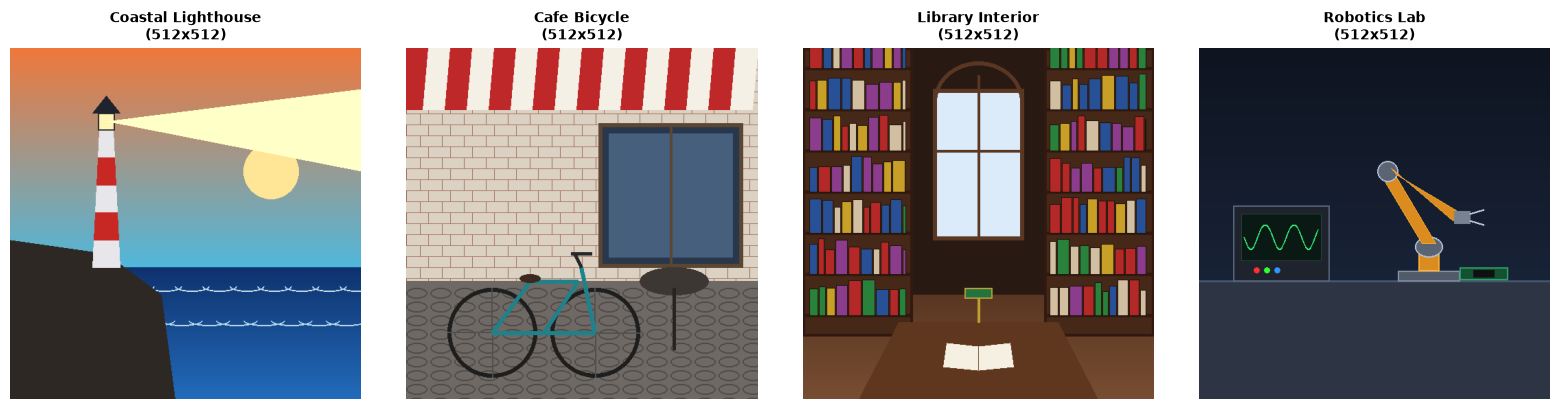

,file_name,scene,category,dimensions,aspect_ratio,format,file_size_kb,mean_rgb
0,01_coastal_lighthouse.png,Coastal Lighthouse,Landscape / Maritime,512x512,1.00,PNG,6.16,"(122.7, 126.8, 128.4)"
1,02_cafe_bicycle.png,Cafe Bicycle,Urban / Street Scene,512x512,1.00,PNG,8.41,"(149.6, 134.3, 130.9)"
2,03_library_interior.png,Library Interior,Interior / Architecture,512x512,1.00,PNG,6.13,"(101.5, 75.6, 67.3)"
3,04_modern_robotics_lab.png,Robotics Lab,Technology / Laboratory,512x512,1.00,PNG,4.72,"(31.8, 38.9, 52.0)"


In [2]:
image_files = [
    {"file": "01_coastal_lighthouse.png", "scene": "Coastal Lighthouse", "category": "Landscape / Maritime"},
    {"file": "02_cafe_bicycle.png", "scene": "Cafe Bicycle", "category": "Urban / Street Scene"},
    {"file": "03_library_interior.png", "scene": "Library Interior", "category": "Interior / Architecture"},
    {"file": "04_modern_robotics_lab.png", "scene": "Robotics Lab", "category": "Technology / Laboratory"}
]

audit_records = []
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for idx, item in enumerate(image_files):
    fpath = INPUTS_DIR / item["file"]
    assert fpath.exists(), f"Зображення {fpath.name} не знайдено!"
    img = Image.open(fpath)
    stat = fpath.stat()
    
    arr = np.array(img.convert("RGB"))
    mean_r, mean_g, mean_b = arr[:, :, 0].mean(), arr[:, :, 1].mean(), arr[:, :, 2].mean()
    
    audit_records.append({
        "file_name": item["file"],
        "scene": item["scene"],
        "category": item["category"],
        "dimensions": f"{img.width}x{img.height}",
        "aspect_ratio": f"{img.width/img.height:.2f}",
        "format": img.format or "PNG",
        "file_size_kb": round(stat.st_size / 1024, 2),
        "mean_rgb": f"({mean_r:.1f}, {mean_g:.1f}, {mean_b:.1f})"
    })
    
    axes[idx].imshow(img)
    axes[idx].set_title(f"{item['scene']}\n({img.width}x{img.height})", fontsize=10, fontweight="bold")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

audit_df = pd.DataFrame(audit_records)
audit_df.to_csv(OUTPUTS_DIR / "tables" / "image_inputs_audit.csv", index=False, encoding="utf-8")
audit_df

## 3. Архітектура моделі LLaVA та ініціалізація ваг

Модель **LLaVA (Large Language and Vision Assistant)** використовує двокомпонентний підхід до мультимодального розуміння:
1. **Vision Tower (SigLIP / CLIP):** Витягує просторові ембеддинги зображення $Z_v = g(X_v) \in \mathbb{R}^{N \times D_v}$, де $N$ — кількість візуальних токенів (патчів), а $D_v$ — вимірність прихованого стану зорового енкодера.
2. **Multimodal Projector:** Лінійна або двошарова MLP-проекція $H_v = W \cdot Z_v$, що трансформує простір візуальних ознак $D_v$ у простір прихованих станів мовної моделі $D_l$.
3. **Large Language Model (Qwen2 Backbone):** Отримує об'єднану послідовність токенів:
$$\text{Input} = [\text{System Tokens}, \ H_v, \ \text{Prompt Tokens}]$$
і генерує відповідь авторегресивним чином за принципом причинного маскування (causal attention).

Для роботи на апаратно обмеженому прискорювачі (RTX 3050 Laptop GPU, 4 ГБ VRAM) використано компактну та високоефективну модель `llava-hf/llava-interleave-qwen-0.5b-hf` у половинній точності `torch.float16`.

In [3]:
from transformers import AutoProcessor, LlavaForConditionalGeneration

MODEL_ID = "llava-hf/llava-interleave-qwen-0.5b-hf"
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print(f"Ініціалізація процесора та ваг моделі {MODEL_ID} на пристрої {device}...")

processor = AutoProcessor.from_pretrained(MODEL_ID, revision="1090956dd1c79bc93ae98dcf395590369435ec91")
model = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID, revision="1090956dd1c79bc93ae98dcf395590369435ec91",
    torch_dtype=torch.float16 if device.startswith("cuda") else torch.float32,
    low_cpu_mem_usage=True
).to(device)
model.eval()

print("✓ Модель LLaVA успішно завантажена та переведена в режим inference (eval).")
print(f"  Кількість параметрів: ~{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")
if torch.cuda.is_available():
    print(f"  Зайнята VRAM після завантаження: {torch.cuda.memory_allocated(0) / (1024**2):.1f} MiB")

Ініціалізація процесора та ваг моделі llava-hf/llava-interleave-qwen-0.5b-hf на пристрої cuda:0...


✓ Модель LLaVA успішно завантажена та переведена в режим inference (eval).
  Кількість параметрів: ~864.0M
  Зайнята VRAM після завантаження: 1678.7 MiB


## 4. Базовий smoke-test мультимодальної генерації

Перевіримо роботу конвеєра на першому вхідному зображенні (Маяк) із лаконічною системною інструкцією.

In [4]:
test_img_path = INPUTS_DIR / "01_coastal_lighthouse.png"
test_image = Image.open(test_img_path).convert("RGB")
prompt_text = "Provide a concise, single-sentence caption describing this image."

formatted_prompt = f"<|im_start|>user\n<image>\n{prompt_text}<|im_end|>\n<|im_start|>assistant\n"
inputs = processor(text=formatted_prompt, images=test_image, return_tensors="pt").to(device, dtype=model.dtype)

with torch.no_grad():
    out_tokens = model.generate(**inputs, max_new_tokens=48, do_sample=False)

new_tokens = out_tokens[0][inputs["input_ids"].shape[1]:]
caption = processor.decode(new_tokens, skip_special_tokens=True).strip()

print(f"Вхідне зображення: {test_img_path.name}")
print(f"Промпт:            {prompt_text}")
print(f"Згенерований опис: {caption}")
print(f"Згенеровано токенів: {len(new_tokens)}")

Вхідне зображення: 01_coastal_lighthouse.png
Промпт:            Provide a concise, single-sentence caption describing this image.
Згенерований опис: A lighthouse on a cliff overlooking the ocean.
Згенеровано токенів: 11


### 4.1 Візуалізація результату базового smoke-test (офлайн-режим)

> **Примітка щодо відтворюваності:** Нижче відображено оригінальне тестове зображення `01_coastal_lighthouse.png` разом із зафіксованим описом smoke-test інференсу вище (`exec=4`) без повторного запуску GPU-генерації.

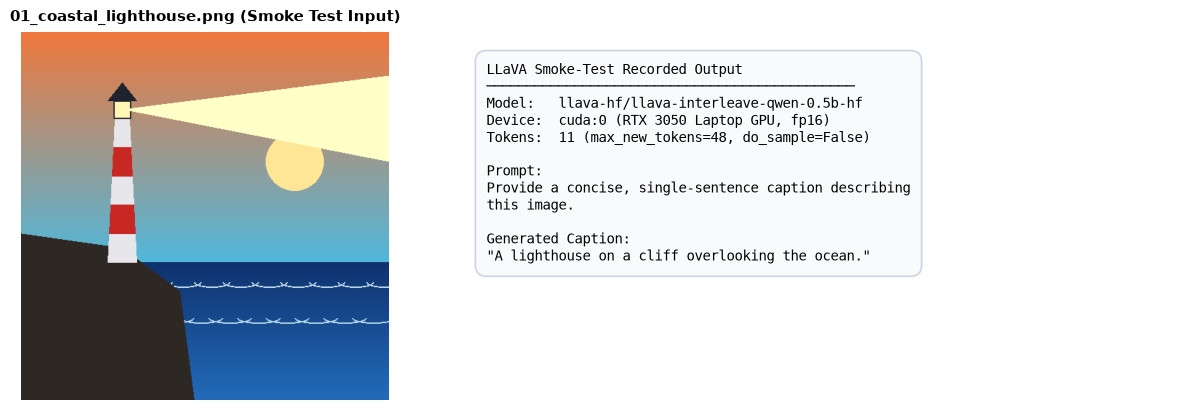

In [5]:
import textwrap
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

_inputs_dir = INPUTS_DIR if "INPUTS_DIR" in globals() else Path("inputs")
_img_path = _inputs_dir / "01_coastal_lighthouse.png"
_prompt_text = (
    prompt_text
    if "prompt_text" in globals()
    else "Provide a concise, single-sentence caption describing this image."
)
_smoke_caption = (
    caption
    if "caption" in globals()
    else "A lighthouse on a cliff overlooking the ocean."
)
_tok_count = len(new_tokens) if "new_tokens" in globals() else 11

fig, (ax_img, ax_txt) = plt.subplots(
    1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.05, 1.35]}
)
ax_img.imshow(Image.open(_img_path).convert("RGB"))
ax_img.set_title("01_coastal_lighthouse.png (Smoke Test Input)", fontsize=10.5, fontweight="bold", pad=8)
ax_img.axis("off")

ax_txt.axis("off")
wrapped_cap = textwrap.fill(_smoke_caption, width=54)
wrapped_prompt = textwrap.fill(_prompt_text, width=56)
card_text = (
    "LLaVA Smoke-Test Recorded Output\n"
    "──────────────────────────────────────────────\n"
    f"Model:   llava-hf/llava-interleave-qwen-0.5b-hf\n"
    f"Device:  cuda:0 (RTX 3050 Laptop GPU, fp16)\n"
    f"Tokens:  {_tok_count} (max_new_tokens=48, do_sample=False)\n\n"
    f"Prompt:\n{wrapped_prompt}\n\n"
    f"Generated Caption:\n\"{wrapped_cap}\""
)
ax_txt.text(
    0.03,
    0.92,
    card_text,
    transform=ax_txt.transAxes,
    va="top",
    ha="left",
    fontsize=10,
    family="monospace",
    bbox={"boxstyle": "round,pad=0.8", "facecolor": "#f8fafc", "edgecolor": "#cbd5e1", "linewidth": 1.2},
)
plt.tight_layout()
plt.show()